In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path.cwd().parent
movies = pd.read_csv(ROOT / "data" / "raw" / "movies.csv")
ratings = pd.read_csv(ROOT / "data" / "raw" / "ratings.csv")
tags = pd.read_csv(ROOT / "data" / "raw" / "tags.csv")

print("Movies:", movies.shape)
print("Ratings:", ratings.shape)
print("Tags:", tags.shape)
print("Users:", ratings["userId"].nunique())

Movies: (9742, 3)
Ratings: (100836, 4)
Tags: (3683, 4)
Users: 610


In [2]:
display(movies.head(20))
movies.info()
ratings.info()

print(movies.isnull().sum())
print(ratings.isnull().sum())
print("Doublons movies:", movies.duplicated().sum())
print("Doublons ratings:", ratings.duplicated().sum())
print("Paires user-film en double:", ratings.duplicated(subset=["userId", "movieId"]).sum())

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy
5,6,Heat (1995),Action|Crime|Thriller
6,7,Sabrina (1995),Comedy|Romance
7,8,Tom and Huck (1995),Adventure|Children
8,9,Sudden Death (1995),Action
9,10,GoldenEye (1995),Action|Adventure|Thriller


<class 'pandas.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   movieId  9742 non-null   int64
 1   title    9742 non-null   str  
 2   genres   9742 non-null   str  
dtypes: int64(1), str(2)
memory usage: 228.5 KB
<class 'pandas.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB
movieId    0
title      0
genres     0
dtype: int64
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64
Doublons movies: 0
Doublons ratings: 0
Paires user-film en double: 0


In [3]:
print(ratings["rating"].describe())
print("Moyenne globale:", ratings["rating"].mean())
print("Films notés:", ratings["movieId"].nunique(), "/", movies["movieId"].nunique())

density = len(ratings) / (ratings["userId"].nunique() * ratings["movieId"].nunique())
print(f"Densité de la matrice: {density:.2%}")

count    100836.000000
mean          3.501557
std           1.042529
min           0.500000
25%           3.000000
50%           3.500000
75%           4.000000
max           5.000000
Name: rating, dtype: float64
Moyenne globale: 3.501556983616962
Films notés: 9724 / 9742
Densité de la matrice: 1.70%


In [4]:
stats = ratings.groupby("movieId").agg(
    rating_count=("rating", "count"),
    average_rating=("rating", "mean")
).reset_index().merge(movies, on="movieId")

print(stats.sort_values("rating_count", ascending=False).head(10)[["title", "rating_count", "average_rating"]])
print(stats[stats["rating_count"] >= 50].sort_values("average_rating", ascending=False).head(10)[["title", "rating_count", "average_rating"]])

                                          title  rating_count  average_rating
314                         Forrest Gump (1994)           329        4.164134
277            Shawshank Redemption, The (1994)           317        4.429022
257                         Pulp Fiction (1994)           307        4.197068
510            Silence of the Lambs, The (1991)           279        4.161290
1938                         Matrix, The (1999)           278        4.192446
224   Star Wars: Episode IV - A New Hope (1977)           251        4.231076
418                        Jurassic Park (1993)           238        3.750000
97                            Braveheart (1995)           237        4.031646
507           Terminator 2: Judgment Day (1991)           224        3.970982
461                     Schindler's List (1993)           220        4.225000
                                                  title  rating_count  \
277                    Shawshank Redemption, The (1994)           317

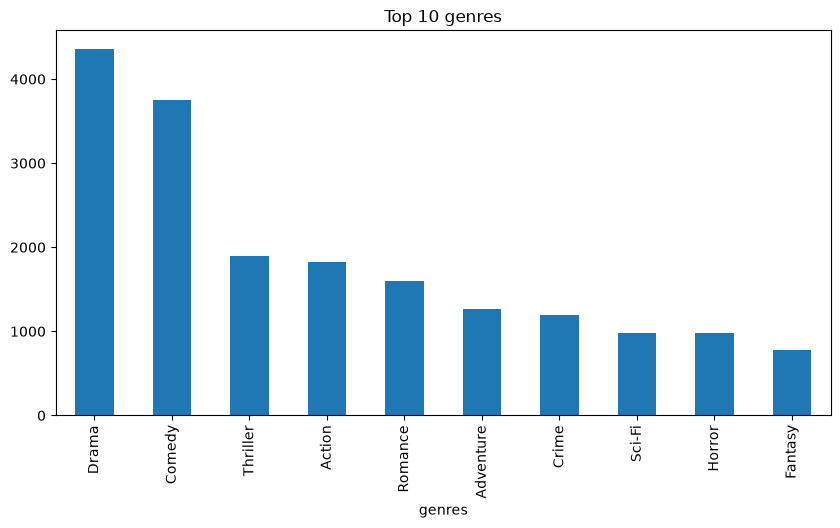

In [5]:
genres = movies["genres"].str.split("|").explode()
genres.value_counts().head(10).plot(kind="bar", figsize=(10, 5), title="Top 10 genres")
plt.show()

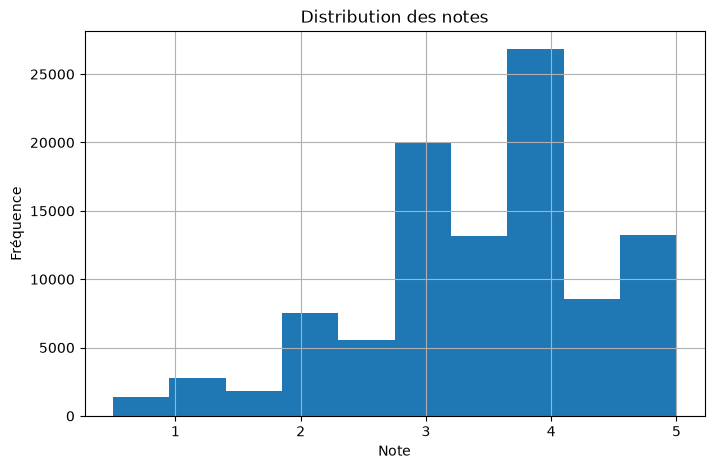

In [6]:
ratings["rating"].hist(bins=10, figsize=(8, 5))
plt.title("Distribution des notes")
plt.xlabel("Note")
plt.ylabel("Fréquence")
plt.show()

In [7]:
per_user = ratings.groupby("userId").size()
print(per_user.describe())
print(per_user.sort_values(ascending=False).head(10))
print("Utilisateurs avec moins de 3 notes:", (per_user < 3).sum())

per_movie = ratings.groupby("movieId").size()
print("Films avec une seule note:", (per_movie == 1).sum())

count     610.000000
mean      165.304918
std       269.480584
min        20.000000
25%        35.000000
50%        70.500000
75%       168.000000
max      2698.000000
dtype: float64
userId
414    2698
599    2478
474    2108
448    1864
274    1346
610    1302
68     1260
380    1218
606    1115
288    1055
dtype: int64
Utilisateurs avec moins de 3 notes: 0
Films avec une seule note: 3446


**Interprétation**
- 610 utilisateurs, chacun avec au moins 20 notes : aucun cas à exclure pour manque d'historique.
- Forte asymétrie : médiane de 70 notes contre une moyenne de 165, avec un maximum de 2 698. Quelques utilisateurs très actifs peuvent dominer les statistiques globales.
- 3 446 films n'ont qu'une seule note : problème de démarrage à froid pour le filtrage collaboratif.
- Les notes se concentrent entre 3 et 5 : la cible « aime » (≥ 4) est à vérifier pour le déséquilibre.

In [8]:
print(ratings["rating"].value_counts(normalize=True).sort_index())
print("Part des notes >= 4:", (ratings["rating"] >= 4).mean())

density = len(ratings) / (ratings["userId"].nunique() * ratings["movieId"].nunique())
print(f"Densité de la matrice: {density:.2%}")

top = ratings.groupby("userId").size().sort_values(ascending=False).head(10)
print("Part des 10 plus gros utilisateurs:", top.sum() / len(ratings))

rating
0.5    0.013586
1.0    0.027877
1.5    0.017762
2.0    0.074884
2.5    0.055040
3.0    0.198808
3.5    0.130271
4.0    0.265957
4.5    0.084801
5.0    0.131015
Name: proportion, dtype: float64
Part des notes >= 4: 0.4817723828791305
Densité de la matrice: 1.70%
Part des 10 plus gros utilisateurs: 0.1630766789638621
